# Import Packages/Libraries and Data

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# text processing libraries
import re #regular expressions, die wir später beim Processing brauchen
import string
import nltk

# Suppress warnings 
import warnings
warnings.filterwarnings('ignore')

In [3]:
pip install --upgrade pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install openpyxl --upgrade

Note: you may need to restart the kernel to use updated packages.


In [5]:
df=pd.read_excel('AI in Action_Negoisst-Training-Data.xlsx', index_col=0)  

In [6]:
df.head()

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content
ExperimentID,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo..."
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo..."
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ..."
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last..."
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ..."


# 1) EDA

In [8]:
df.shape

(1150, 6)

In [9]:
df.isnull().sum()

NegotiationID    0
SenderID         0
ReceiverID       0
ActionType       0
NegoOutcome      0
Content          0
dtype: int64

In [10]:
#Anzahl der Zeichen
df['Length'] = df['Content'].str.len()
df.head(10)

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length
ExperimentID,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nYour last offer was a great ...",479
2020_12,65172,65159,65162,FinalAccept,FinalAccept,"Dear Mr. Williams, \nthank you for the pleasa...",393
2020_12,65200,65187,65190,Offer,FinalAccept,"Dear InnoVax Team, \nFirst of all, I would lik...",604
2020_12,65200,65190,65187,Counteroffer,FinalAccept,Dear Michael Brown \nNice to meet you! It is a...,383


In [11]:
#Word Count

def word_count(content):
    content_list = content.split()
    return len(content_list)

df['Word_count of negotiation message'] = df['Content'].apply(word_count)
df.head(10)

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length,Word_count of negotiation message
ExperimentID,,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250,227
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254,219
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467,252
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857,157
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686,124
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nYour last offer was a great ...",479,95
2020_12,65172,65159,65162,FinalAccept,FinalAccept,"Dear Mr. Williams, \nthank you for the pleasa...",393,69
2020_12,65200,65187,65190,Offer,FinalAccept,"Dear InnoVax Team, \nFirst of all, I would lik...",604,103
2020_12,65200,65190,65187,Counteroffer,FinalAccept,Dear Michael Brown \nNice to meet you! It is a...,383,70


<Axes: >

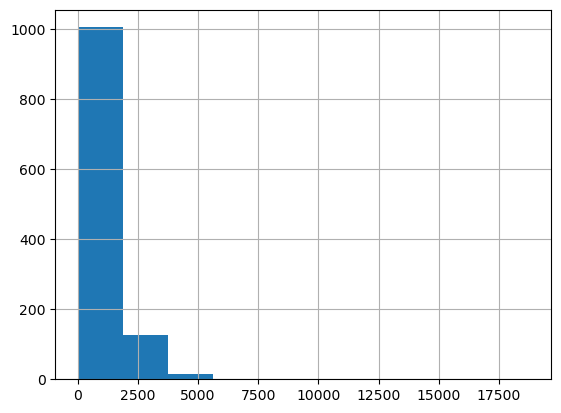

In [12]:
#Histogramm auf der Zeichenebene
df['Content'].str.len().hist()

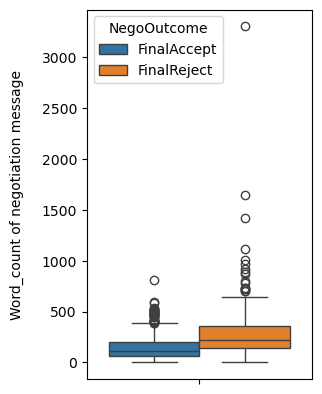

In [13]:
#Visualization der oben generierten Kennzahlen
#Eindruck darüber gewinnen wie sich diese verteilen mit Blick auf Acc/Rej.

def visualize(col):
    
    print()
    plt.subplot(1,2,1)
    sns.boxplot(y=df[col], hue=df['NegoOutcome'])
    plt.ylabel(col, labelpad=12.5)
    plt.show()

#Angefangen vom 7.Element ab 0 zählend, in meinem Fall ab Length anfangen
attributes = df.columns.tolist()[7:]
for column in attributes:
    visualize(column)

In [14]:
#Ein Blick auf die TargetClasss Accept und Reject

In [15]:
df['NegoOutcome'].value_counts()

NegoOutcome
FinalAccept    850
FinalReject    300
Name: count, dtype: int64

In [16]:
accepted_messages = df[df['NegoOutcome']=='FinalAccept']['Content']
accepted_messages.values[1]

"Dear Mr. Brown, \nI am pleased to hear from you.Thank you for your last message. Unfortunately, there are still a few open points that I cannot accept and have to be renegotiated.In the attachments, you can find my first offer.I would aim for the best possible outcome for us both and with this cooperation, we could stop the spread of this disease, therefore I am of course willing to negotiate certain points in open communication. I comprehend your point of view and your situation to need the vaccination very quickly but we from InnoVax need a few more months to be able to produce the requested amount.Concerning the guarantee, we are open to conceding a\xa0Wide\xa0Guarantee\xa0which is a very good level of guarantee. About the price, your suggestion is unfortunately very unacceptable. The development of a vaccine is an expensive process and we make sure that it was made by the best experts from all over the world during long-time research. This is also our big concern and we suggest a 

In [17]:
accepted_messages.count()

850

In [18]:
rejected_messages = df[df['NegoOutcome']=='FinalReject']['Content']
rejected_messages.values[1]

"Dear Dennis Williams, \nThank you for your message! The negotiation will be hard if you consider all topics as very important. But first of all, thank you for your first offer. Our opinions differ on crucial points, I therefore would like to discuss some points regarding the mentioned issues with you. But I am pretty sure, that we can find a good solution for both of us if we concede some issues. In attachment you can find my counteroffer. \nRegarding the delivery time I think your offer of 7 months is quite late. It would be nice if you could explain why your company needs seven months for delivery. You should also consider your competitor from France when making your decision. Your competitor will have a vaccine ready in about six months. Therefore, we would not have a benefit choosing Innovax as our partner when you deliver your vaccine in 7 months. And I think that the start of the field test is important for both of us. So therefore as\xa0Delivery Time\xa0I offer you\xa01 month\x

In [19]:
rejected_messages.count()

300

In [20]:
#LabelTargetVariable 'NegoOutcome' 
from sklearn import preprocessing

'''
le = preprocessing.LabelEncoder()
df['NegoOutcome'] = le.fit_transform(df['NegoOutcome'])
df.NegoOutcome
'''

df['NegoOutcomeLabel'] = df.NegoOutcome.map({'FinalReject':0, 'FinalAccept':1})
df.head()

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length,Word_count of negotiation message,NegoOutcomeLabel
ExperimentID,,,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250,227,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254,219,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467,252,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857,157,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686,124,1


In [21]:
pip install wordcloud

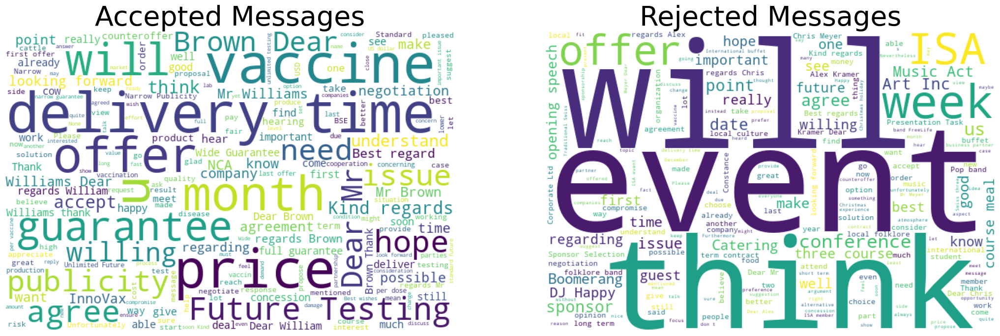

In [22]:
from wordcloud import WordCloud

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[26, 8])

wordcloud1 = WordCloud( background_color='white',
                        width=600,
                        height=400).generate(" ".join(accepted_messages))
ax1.imshow(wordcloud1)
ax1.axis('off')
ax1.set_title('Accepted Messages',fontsize=40);

wordcloud2 = WordCloud( background_color='white',
                        width=600,
                        height=400).generate(" ".join(rejected_messages))
ax2.imshow(wordcloud2)
ax2.axis('off')
ax2.set_title('Rejected Messages',fontsize=40);

In [23]:
#Anzahl der Nachrichten wo das Wort auftaucht durch Gesamtanzahl
print("The total rate of the word event in rejected messages is: ", 
      sum(rejected_messages.str.contains('event'))/len(rejected_messages))

The total rate of the word event in rejected messages is:  0.6033333333333334


In [24]:
# an den Ergebnissen sehen wir, dass wir die Texte noch verarbeiten müssen und hier noch Case-Spezifische Informationen
#enthalten sind, die uns nicht wirklich interessieren, da wir ja herausfinden wollen, weshalb die Verhandlung gescheitert 
#ist.

In [25]:
#Hinweis, dass ein Teil des EDA-Prozesses vor der Bereinigung und ein anderer erst nach der Quantifizierung der NLP erfoolgen kann, siehe später.

# 2) Text Processing

## 2.1) Text Cleansing

In [28]:
all_messages = df["Content"]
all_messages.head()

ExperimentID
2020_12     \nDear Mr. Williams, \nI am happy to be respo...
2020_12    Dear Mr. Brown, \nI am pleased to hear from yo...
2020_12    Dear Mr. Williams, \nthank you for your quick ...
2020_12    Dear Mr. Brown, \nThe concessions of your last...
2020_12    Dear Mr. Williams,  \nthank you very much for ...
Name: Content, dtype: object

In [29]:
#Cleaning the Corpus 
'''Make text lowercase, remove text in square brackets,remove links,remove punctuation
    and remove words containing numbers.'''

def clean_text(message):
    #lowercasing
    message = message.lower()
    
    #regular expressions, gerne mal nachschauen wie das funktioniert
    message = re.sub('\[.*?\]', '', message)
    message = re.sub('https?://\S+|www\.\S+', '', message)
    message = re.sub('<.*?>+', '', message)
    message = re.sub('[%s]' % re.escape(string.punctuation), '', message)
    message = re.sub('\n', '', message)
    message = re.sub('\w*\d\w*', '', message)
    
    return message

# Applying the cleaning function to the content column
df['Content'] = df['Content'].apply(lambda x: clean_text(x))

# Let's take a look at the updated messages
df['Content'].head()

ExperimentID
2020_12     dear mr williams i am happy to be responsible...
2020_12    dear mr brown i am pleased to hear from youtha...
2020_12    dear mr williams thank you for your quick and ...
2020_12    dear mr brown the concessions of your last off...
2020_12    dear mr williams  thank you very much for your...
Name: Content, dtype: object

## 2.2) Tokenization

In [31]:
# Bereinigte Sätze in Word-Tokens aufgerteilt

tokenizer = nltk.tokenize.RegexpTokenizer(r'\w+')
df['Content'] = df['Content'].apply(lambda x: tokenizer.tokenize(x))
df['Content'].head()

ExperimentID
2020_12    [dear, mr, williams, i, am, happy, to, be, res...
2020_12    [dear, mr, brown, i, am, pleased, to, hear, fr...
2020_12    [dear, mr, williams, thank, you, for, your, qu...
2020_12    [dear, mr, brown, the, concessions, of, your, ...
2020_12    [dear, mr, williams, thank, you, very, much, f...
Name: Content, dtype: object

## 2.3) Stopword Removal

In [33]:
from nltk.corpus import stopwords

#stopword removal
#Often we want to remove stopwords when we want to keep the "gist" of the document/sentence.
stopwords_en = stopwords.words('english')
print(stopwords_en)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [34]:
 #Vordefinierte Stopword-Liste von NLTK vorhanden
# Removing stopwords belonging to english language
    
def remove_stopwords(text):
    words = [w for w in text if w not in stopwords.words('english')]
    return words

df['Content'] = df['Content'].apply(lambda x : remove_stopwords(x))
df['Content'].head()

ExperimentID
2020_12    [dear, mr, williams, happy, responsible, negot...
2020_12    [dear, mr, brown, pleased, hear, youthank, las...
2020_12    [dear, mr, williams, thank, quick, cooperative...
2020_12    [dear, mr, brown, concessions, last, offer, sh...
2020_12    [dear, mr, williams, thank, much, response, ha...
Name: Content, dtype: object

## 2.4) Token Normalisation

Short Example for Stemming & Lemmatization - see Theory for Details

In [37]:
#Normalization of tokens ---> explain Stemming and Lemmatization in Theory
#Example to see one example in Stemming and Lemmatization: 

text = "I welcome you all in the AI in Action course of the intelligent information systems chair"

tokenizer = nltk.tokenize.TreebankWordTokenizer()
tokens = tokenizer.tokenize(text)

# Stemmer
stemmer = nltk.stem.PorterStemmer()
print("Stemming the sentence: ", " ".join(stemmer.stem(token) for token in tokens))

# Lemmatizer
lemmatizer=nltk.stem.WordNetLemmatizer()
print("Lemmatizing the sentence: ", " ".join(lemmatizer.lemmatize(token) for token in tokens))

Stemming the sentence:  i welcom you all in the ai in action cours of the intellig inform system chair
Lemmatizing the sentence:  I welcome you all in the AI in Action course of the intelligent information system chair


In [38]:
#Lemmatization Platzhalter --> nicht angewandt
'''
It is important to note here that stemming and lemmatization sometimes donot necessarily improve results as at times we donot want to trim words but rather preserve their original form. Hence their usage actually differs from problem to problem. For this problem, I will not use these techniques.
'''

# After preprocessing, the text format
# wörter wieder zusammensetzen
def combine_text(list_of_text):
    '''Takes a list of text and combines them into one large chunk of text.'''
    combined_text = ' '.join(list_of_text)
    return combined_text

df['Content'] = df['Content'].apply(lambda x : combine_text(x))

#DIESES DF[CONTENT] WERDEN WIR IMMER WIEDER EINLESEN; DAS NEHMEN WIR ALS DATENBASIS AN
df['Content']


ExperimentID
2020_12    dear mr williams happy responsible negotiation...
2020_12    dear mr brown pleased hear youthank last messa...
2020_12    dear mr williams thank quick cooperative respo...
2020_12    dear mr brown concessions last offer showed ri...
2020_12    dear mr williams thank much response happy fou...
                                 ...                        
2020_06    dear chis meyer thank latest offer points comp...
2020_06    dear alex kramerthank much latest offer happy ...
2020_06    dear chris meyerthank fast answer happy found ...
2020_06    dear alex krameri still interested coming join...
2020_06    dear chris meyer im sorry accept less mei unde...
Name: Content, Length: 1150, dtype: object

In [39]:
df.head()

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length,Word_count of negotiation message,NegoOutcomeLabel
ExperimentID,,,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,dear mr williams happy responsible negotiation...,1250,227,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,dear mr brown pleased hear youthank last messa...,1254,219,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,dear mr williams thank quick cooperative respo...,1467,252,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,dear mr brown concessions last offer showed ri...,857,157,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,dear mr williams thank much response happy fou...,686,124,1


# 3) Text Representation/Transformation/Vectorization

## 3.1) Corpus and Corpus-based EDA

In [42]:
# Als vorbereitender Schritt wird vor der Vektorisierung mal ein Korpus gebaut
corpus=[]
new= df['Content'].str.split()
new=new.values.tolist()
corpus=[word for i in new for word in i]

In [43]:
corpus

['dear',
 'mr',
 'williams',
 'happy',
 'responsible',
 'negotiation',
 'representative',
 'innovax',
 'settle',
 'last',
 'issuesyou',
 'certainly',
 'aware',
 'outbreak',
 'bse',
 'pandemic',
 'great',
 'concern',
 'association',
 'determined',
 'stop',
 'spread',
 'disease',
 'vaccination',
 'therefore',
 'looking',
 'come',
 'agreement',
 'strongly',
 'believe',
 'able',
 'reach',
 'agreement',
 'suits',
 'us',
 'communicate',
 'well',
 'therefore',
 'willing',
 'communicate',
 'openly',
 'regarding',
 'importance',
 'different',
 'issues',
 'delivery',
 'time',
 'one',
 'important',
 'issues',
 'us',
 'would',
 'like',
 'vaccine',
 'soon',
 'possible',
 'ideally',
 'month',
 'another',
 'important',
 'issue',
 'guarantee',
 'ideally',
 'agree',
 'full',
 'guarantee',
 'since',
 'need',
 'compensation',
 'damages',
 'occur',
 'moreover',
 'price',
 'another',
 'big',
 'concern',
 'would',
 'suggest',
 'price',
 'usd',
 'two',
 'issues',
 'certainly',
 'important',
 'well',
 'leave'

In [44]:
#Anzahl der Wörter im Korpus --> auch Dopplungen im Korpus vorhanden natürlich, daher die Zahl so hoch. 
len(corpus)

101853

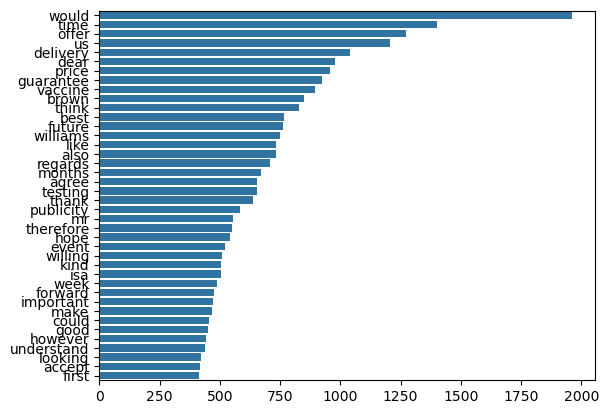

In [45]:
from collections import  Counter

#Top Words, die sich im derzeitigen Corpus befinden nach Häufigkeit sortiert
def plot_topwords_barchart(message):
    new=message.str.split()
    new=new.values.tolist()
    corpus=[word for i in new for word in i]

    counter=Counter(corpus)
    most=counter.most_common()
    x, y=[], []
    
    for word, count in most[:40]:
            x.append(word)
            y.append(count)
            
    sns.barplot(x=y,y=x)

plot_topwords_barchart(df['Content'])

## 3.2) Vectorization

In [47]:
#Im folgenden werden wir schrittweise verschiedene Repräsentationsarten kennenlernen

### 3.2.1) BoW

In [49]:
# sklearn 
from sklearn.feature_extraction.text import CountVectorizer

In [50]:
#BoW
'''
Countvectorizer converts a collection of text documents to a matrix of token counts.
'''
#man kann über den CountVecotizer auch bspw. stop-Words entfernen, haben wir aber schon daher lassen wir das nachfolgende Objekt leer
count_vectorizer = CountVectorizer()
message_vectors = count_vectorizer.fit_transform(df['Content'])
message_vectors 

<1150x5996 sparse matrix of type '<class 'numpy.int64'>'
	with 79004 stored elements in Compressed Sparse Row format>

In [51]:
#Nachfolgende Schritte um den Count Vectorizer ausgeben zu können
message_array = message_vectors.toarray()
df_countvectorizer = pd.DataFrame(data=message_array,columns = count_vectorizer.get_feature_names_out())
print(df_countvectorizer)

      abandon  abe  abilities  ability  abilty  able  abovementioned  abroad  \
0           0    0          0        0       0     1               0       0   
1           0    0          0        0       0     1               0       0   
2           0    0          0        0       0     2               0       0   
3           0    0          0        0       0     0               0       0   
4           0    0          0        0       0     1               0       0   
...       ...  ...        ...      ...     ...   ...             ...     ...   
1145        0    0          0        0       0     0               0       0   
1146        0    0          0        0       0     0               0       0   
1147        0    0          0        0       0     0               0       0   
1148        0    0          0        0       0     0               0       0   
1149        0    0          0        0       0     0               0       0   

      absence  absences  ...  youwillia

In [52]:
#So kann man sich ausgeben lassen welche Worte das sind (vereinheitlicht)
df_countvectorizer.columns

Index(['abandon', 'abe', 'abilities', 'ability', 'abilty', 'able',
       'abovementioned', 'abroad', 'absence', 'absences',
       ...
       'youwilliams', 'youwith', 'yy', 'zealand', 'zoom', 'zurich', 'zurick',
       'zürich', 'às', 'ánd'],
      dtype='object', length=5996)

In [53]:
#BoW-Alternative with n-grams
'''
#Set the parameter ngram_range=(a,b) where a is the minimum and b is the maximum size of ngrams
#min_df = 0.01 means "ignore terms that appear in less than 1% of the documents".
# max_df = 0.50 means "ignore terms that appear in more than 50% of the documents".
# max_features: This parameter is pretty self-explanatory. The CountVectorizer will choose the words/features that occur most frequently to be in its’ 
#vocabulary and drop everything else.
'''

#Hier auf max. 100 Dimensionen eingeschränkt unter Berücksichtigung der anderen Kennzahlen
count_vectorizer_ngram = CountVectorizer(ngram_range=(1,2), min_df=0.1, max_df=0.7, max_features=100)
message_vectors_ngram = count_vectorizer_ngram.fit_transform(df['Content'])

In [54]:
message_vectors_ngram.shape

(1150, 100)

In [55]:
#Nachfolgende Schritte um den n-gram based Count Vectorizer ausgeben zu können
message_ngram_array = message_vectors_ngram.toarray()
df_countvectorizer_ngram = pd.DataFrame(data=message_ngram_array, columns = count_vectorizer_ngram.get_feature_names_out())
print(df_countvectorizer_ngram)

      able  accept  agree  agreement  alex  already  also  band  best  \
0        1       0      1          2     0        0     0     0     1   
1        1       1      0          0     0        0     1     0     2   
2        2       5      0          0     0        0     0     0     1   
3        0       1      0          2     0        1     2     0     1   
4        1       0      0          1     0        0     0     0     1   
...    ...     ...    ...        ...   ...      ...   ...   ...   ...   
1145     0       0      0          0     0        0     3     3     2   
1146     0       1      1          1     1        1     0     3     0   
1147     0       0      0          0     0        1     0     2     1   
1148     0       3      0          0     1        1     0     1     1   
1149     0       1      0          0     0        0     0     0     1   

      best regards  ...  want  way  week  well  wide  williams  willing  work  \
0                1  ...     0    0     0  

In [56]:
#alle 100 n-grams (man kann natürlich auch mehr bilden und weitere selektionsansätze durchführen)
df_countvectorizer_ngram.columns

Index(['able', 'accept', 'agree', 'agreement', 'alex', 'already', 'also',
       'band', 'best', 'best regards', 'brown', 'chris', 'come', 'company',
       'conference', 'could', 'course', 'deal', 'dear mr', 'delivery',
       'delivery time', 'event', 'find', 'first', 'forward', 'full',
       'full guarantee', 'future', 'future testing', 'get', 'give', 'good',
       'great', 'guarantee', 'happy', 'hear', 'hope', 'however', 'important',
       'innovax', 'international', 'isa', 'issue', 'issues', 'kind',
       'kind regards', 'know', 'last', 'like', 'looking', 'looking forward',
       'make', 'months', 'mr', 'mr brown', 'mr williams', 'much', 'music',
       'narrow', 'nca', 'need', 'negotiation', 'new', 'offer', 'one', 'per',
       'please', 'point', 'possible', 'price', 'publicity', 'really',
       'regarding', 'regards', 'see', 'since', 'soon', 'sponsor', 'still',
       'take', 'testing', 'thank', 'therefore', 'think', 'time', 'time months',
       'understand', 'us', 'vacci

### 3.2.2) TF-IDF

In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

#TF-IDF

tfidf_vectorizer = TfidfVectorizer()
tfidf_vectorizer.fit(df['Content'])
tfidf_message_vector = tfidf_vectorizer.transform(df['Content'])

#Gleiches Spiel mit dem min_df, max_df usw. siehe auch hier bei dem Tokenizer erweiterbar, siehe Dokumentation


In [59]:
#Anzahl der Dimensionen identisch zu BoW hoch. Passt auch, da bei TF-IDF keine Dimensionskürzung vorgenommen wird
#Die Berechnungsgrundlage für die Kennzahlen ist hier einfach eine andere
tfidf_message_vector.shape

(1150, 5996)

In [60]:
message_tfidf_array = tfidf_message_vector.toarray()
df_tfidf = pd.DataFrame(data=message_tfidf_array, columns = tfidf_vectorizer.get_feature_names_out())
print(df_tfidf)

      abandon  abe  abilities  ability  abilty      able  abovementioned  \
0         0.0  0.0        0.0      0.0     0.0  0.065453             0.0   
1         0.0  0.0        0.0      0.0     0.0  0.064970             0.0   
2         0.0  0.0        0.0      0.0     0.0  0.112407             0.0   
3         0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
4         0.0  0.0        0.0      0.0     0.0  0.099584             0.0   
...       ...  ...        ...      ...     ...       ...             ...   
1145      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1146      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1147      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1148      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1149      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   

      abroad  absence  absences  ...  youwilliams   youwith   yy  zealand  \
0        0

### 3.2.3) Word Embeddings

In [62]:
#Word2Vec, Glove mal vorkodieren mit Hinweis dass es darüber hinaus noch mehr gibt

In [63]:
pip install scipy==1.12

Note: you may need to restart the kernel to use updated packages.


In [64]:
#falls der vorhergehende Code nicht weiterhilft in Kombination mit diesem hier mal probieren
# der Herr hat soll das Problem in seinem GitHub gefixt haben

#pip install git+https://github.com/piskvorky/gensim.git

Word2Vec - start with Pre-Trained from Google

In [66]:
#Word2Vec herunterladen über NLTK, damit wir auf das Pre-Training zugreifen können
import nltk
nltk.download('word2vec_sample')

[nltk_data] Downloading package word2vec_sample to
[nltk_data]     C:\Users\Kaya\AppData\Roaming\nltk_data...
[nltk_data]   Package word2vec_sample is already up-to-date!


True

In [67]:
'''
NLTK includes a pre-trained model which is part of a model that is trained on 100 billion words from the Google News Dataset. 
The full model is from https://code.google.com/p/word2vec/ (about 3 GB).
'''

'''
Word2Vec is one of the most popular pretrained word embeddings developed by Google. 
Word2Vec is trained on the Google News dataset (about 100 billion words). 
It has several use cases such as Recommendation Engines, Knowledge Discovery, and also applied in the different Text Classification problems.
The architecture of Word2Vec is really simple. It’s a feed-forward neural network with just one hidden layer. 
Hence, it is sometimes referred to as a Shallow Neural Network architecture.
'''

#das hier ist die Pruned variante mit 40k Wörtern 
# https://www.nltk.org/howto/gensim.html

import gensim
from nltk.data import find
word2vec_sample = str(find('models/word2vec_sample/pruned.word2vec.txt'))
pre_w2v_model = gensim.models.KeyedVectors.load_word2vec_format(word2vec_sample, binary=False)

In [68]:
#Versionscheck
print(gensim.__version__)

4.3.2


In [69]:
#Embedding mit ca. 44k Semantischen Wortbeziehungen
len(pre_w2v_model.key_to_index)

43981

In [70]:
#Each word is represented in the space of 300 dimensions
len(pre_w2v_model['negotiation'])

300

In [71]:
pre_w2v_model.most_similar(positive=['negotiation'], topn = 3)

[('negotiations', 0.816856861114502),
 ('negotiating', 0.7531847953796387),
 ('bargaining', 0.6434565782546997)]

In [72]:
#Beispielhafter Vektor über 300 Dimensionen
pre_w2v_model["negotiation"]

array([ 0.00503933,  0.0736899 , -0.0289142 ,  0.0624547 ,  0.0555153 ,
       -0.00116173,  0.0282533 , -0.0617938 ,  0.0565066 ,  0.0799685 ,
       -0.105743  ,  0.0134658 , -0.0305665 ,  0.0114005 , -0.107065  ,
        0.0806294 ,  0.1183    ,  0.00462627,  0.0256097 , -0.0156963 ,
        0.00078481,  0.067081  ,  0.00380015,  0.0852556 ,  0.0328796 ,
        0.0591502 , -0.109709  , -0.073029  ,  0.00805467, -0.044941  ,
        0.00305665, -0.0213139 , -0.0421321 ,  0.0456018 ,  0.0859165 ,
        0.0627852 , -0.00082612,  0.00636113,  0.0684028 , -0.148041  ,
        0.041306  ,  0.0391581 , -0.0366797 ,  0.0156137 , -0.15465   ,
        0.0105743 ,  0.00328383,  0.0137962 , -0.136145  ,  0.0845947 ,
       -0.00850904, -0.00950039, -0.0489063 , -0.035358  , -0.016605  ,
        0.0342014 ,  0.0472541 ,  0.00570023,  0.0614634 ,  0.041306  ,
       -0.142754  ,  0.0555153 , -0.0290794 ,  0.1031    ,  0.0138788 ,
        0.0829425 ,  0.03321   ,  0.0345318 ,  0.027262  , -0.11

In [73]:
pre_w2v_model.most_similar(positive=['disappointed'], topn = 5)

[('dismayed', 0.7374081611633301),
 ('surprised', 0.7143489718437195),
 ('displeased', 0.6827142238616943),
 ('saddened', 0.6556360125541687),
 ('pleased', 0.6533657312393188)]

In [74]:
#beim pre-trained w2vec keine Anwendung auf den zugrundeliegenden Textdaten notwendig
# diese werden erst bei der Modellierung zusammengeführt, Bsp. für LSTM:

'''
embedding_vectors = get_weight_matrix(w2v_model, word_index)
'''

'\nembedding_vectors = get_weight_matrix(w2v_model, word_index)\n'

Originales Word2Vec (nachfolgend) - nur zum Andiskutieren/nicht zeigen

In [76]:

'''
Pre-trained 300-dimensional vectors for about 3 million words and phrases, trained on a portion of the Google News dataset.

--> diese Version inkl. der nachfolgenden LOCs zuhause mal probieren, originales W2Vec ist nämlich zwischen 1,5gb und 3gb groß.
'''

#Download from Google or else: 
# https://www.kaggle.com/datasets/sugataghosh/google-word2vec?resource=download

'\nPre-trained 300-dimensional vectors for about 3 million words and phrases, trained on a portion of the Google News dataset.\n\n--> diese Version inkl. der nachfolgenden LOCs zuhause mal probieren, originales W2Vec ist nämlich zwischen 1,5gb und 3gb groß.\n'

In [77]:
#um das originale herunterzuladen das auskommentierte herunterladen und dann Schritte aus vorhergehenden anwenden
# im Kurs nicht durchführen, das dauert zu lange

'''
import gensim.downloader as api
wv = api.load('word2vec-google-news-300')
'''

"\nimport gensim.downloader as api\nwv = api.load('word2vec-google-news-300')\n"

In [78]:
# Hinweis, dass über t-sne auch visualisierbar
# Pre-trained hat natürlich den Bias, dass dieses nicht auf den Korpus zugeschnitten trainiert wurde, sondern generell auf Google-Beiträgen 

Word2Vec - Self-Trained - hier weitercodieren

In [80]:
#Als Vorbereitung wollen wir in den nachfolgenden LOCs unseren Nego-Message_Daten erstmal vorbereiten:

In [81]:
#Was ist unsere Datenbasis? Wiederholung: 
df['Content']

ExperimentID
2020_12    dear mr williams happy responsible negotiation...
2020_12    dear mr brown pleased hear youthank last messa...
2020_12    dear mr williams thank quick cooperative respo...
2020_12    dear mr brown concessions last offer showed ri...
2020_12    dear mr williams thank much response happy fou...
                                 ...                        
2020_06    dear chis meyer thank latest offer points comp...
2020_06    dear alex kramerthank much latest offer happy ...
2020_06    dear chris meyerthank fast answer happy found ...
2020_06    dear alex krameri still interested coming join...
2020_06    dear chris meyer im sorry accept less mei unde...
Name: Content, Length: 1150, dtype: object

In [82]:
#Zwischenspeichern
nego_message_data = df['Content']
nego_message_data

ExperimentID
2020_12    dear mr williams happy responsible negotiation...
2020_12    dear mr brown pleased hear youthank last messa...
2020_12    dear mr williams thank quick cooperative respo...
2020_12    dear mr brown concessions last offer showed ri...
2020_12    dear mr williams thank much response happy fou...
                                 ...                        
2020_06    dear chis meyer thank latest offer points comp...
2020_06    dear alex kramerthank much latest offer happy ...
2020_06    dear chris meyerthank fast answer happy found ...
2020_06    dear alex krameri still interested coming join...
2020_06    dear chris meyer im sorry accept less mei unde...
Name: Content, Length: 1150, dtype: object

In [83]:
#df bauen
df_nego_message_data = pd.DataFrame(nego_message_data)
df_nego_message_data

,Content
ExperimentID,
2020_12,dear mr williams happy responsible negotiation...
2020_12,dear mr brown pleased hear youthank last messa...
2020_12,dear mr williams thank quick cooperative respo...
2020_12,dear mr brown concessions last offer showed ri...
2020_12,dear mr williams thank much response happy fou...
...,...
2020_06,dear chis meyer thank latest offer points comp...
2020_06,dear alex kramerthank much latest offer happy ...
2020_06,dear chris meyerthank fast answer happy found ...


In [84]:
#Tokenisierung nochmal durchführen (jetzt mal einen anderen Weg ohne RegEx)
from nltk.tokenize import word_tokenize
nltk.download('punkt')

df_nego_message_data['Tokenized_Content'] = df_nego_message_data['Content'].apply(word_tokenize)
df_nego_message_data

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Kaya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,Content,Tokenized_Content
ExperimentID,,
2020_12,dear mr williams happy responsible negotiation...,"[dear, mr, williams, happy, responsible, negot..."
2020_12,dear mr brown pleased hear youthank last messa...,"[dear, mr, brown, pleased, hear, youthank, las..."
2020_12,dear mr williams thank quick cooperative respo...,"[dear, mr, williams, thank, quick, cooperative..."
2020_12,dear mr brown concessions last offer showed ri...,"[dear, mr, brown, concessions, last, offer, sh..."
2020_12,dear mr williams thank much response happy fou...,"[dear, mr, williams, thank, much, response, ha..."
...,...,...
2020_06,dear chis meyer thank latest offer points comp...,"[dear, chis, meyer, thank, latest, offer, poin..."
2020_06,dear alex kramerthank much latest offer happy ...,"[dear, alex, kramerthank, much, latest, offer,..."
2020_06,dear chris meyerthank fast answer happy found ...,"[dear, chris, meyerthank, fast, answer, happy,..."


In [85]:
# Das tokenisierte Format ist nun eine Liste Wörtern
sentences = df_nego_message_data['Tokenized_Content'].tolist()
sentences

[['dear',
  'mr',
  'williams',
  'happy',
  'responsible',
  'negotiation',
  'representative',
  'innovax',
  'settle',
  'last',
  'issuesyou',
  'certainly',
  'aware',
  'outbreak',
  'bse',
  'pandemic',
  'great',
  'concern',
  'association',
  'determined',
  'stop',
  'spread',
  'disease',
  'vaccination',
  'therefore',
  'looking',
  'come',
  'agreement',
  'strongly',
  'believe',
  'able',
  'reach',
  'agreement',
  'suits',
  'us',
  'communicate',
  'well',
  'therefore',
  'willing',
  'communicate',
  'openly',
  'regarding',
  'importance',
  'different',
  'issues',
  'delivery',
  'time',
  'one',
  'important',
  'issues',
  'us',
  'would',
  'like',
  'vaccine',
  'soon',
  'possible',
  'ideally',
  'month',
  'another',
  'important',
  'issue',
  'guarantee',
  'ideally',
  'agree',
  'full',
  'guarantee',
  'since',
  'need',
  'compensation',
  'damages',
  'occur',
  'moreover',
  'price',
  'another',
  'big',
  'concern',
  'would',
  'suggest',
  'p

In [86]:
# vor Präsentation einmal durchgehen was das bedeutet
'''
The parameters of the following Word2Vec model:
    min_count = int - Ignores all words with total absolute frequency lower than this - (2, 100)
    window = int - The maximum distance between the current and predicted word within a sentence. E.g. window words on the left and window words on the left of our target - (2, 10)
    vector_size = int - Dimensionality of the feature vectors. - (50, 300)
    sample = float - The threshold for configuring which higher-frequency words are randomly downsampled. Highly influencial. - (0, 1e-5)
    alpha = float - The initial learning rate - (0.01, 0.05)
    min_alpha = float - Learning rate will linearly drop to min_alpha as training progresses. To set it: alpha - (min_alpha * epochs) ~ 0.00
    negative = int - If > 0, negative sampling will be used, the int for negative specifies how many "noise words" should be drown. If set to 0, no negative sampling is used. - (5, 20)
    workers = int - Use these many worker threads to train the model (=faster training with multicore machines)
'''

'\nThe parameters of the following Word2Vec model:\n    min_count = int - Ignores all words with total absolute frequency lower than this - (2, 100)\n    window = int - The maximum distance between the current and predicted word within a sentence. E.g. window words on the left and window words on the left of our target - (2, 10)\n    vector_size = int - Dimensionality of the feature vectors. - (50, 300)\n    sample = float - The threshold for configuring which higher-frequency words are randomly downsampled. Highly influencial. - (0, 1e-5)\n    alpha = float - The initial learning rate - (0.01, 0.05)\n    min_alpha = float - Learning rate will linearly drop to min_alpha as training progresses. To set it: alpha - (min_alpha * epochs) ~ 0.00\n    negative = int - If > 0, negative sampling will be used, the int for negative specifies how many "noise words" should be drown. If set to 0, no negative sampling is used. - (5, 20)\n    workers = int - Use these many worker threads to train the 

In [87]:
# Word2Vec-Modell trainieren
# Parameter: Größe des Vektorraums, Mindestanzahl an Vorkommen für Wörter, Anzahl der Arbeits-Threads
from gensim.models.word2vec import Word2Vec

ourfirst_w2v_model = Word2Vec(sentences, vector_size=300, window=5, min_count=1, workers=4)
ourfirst_w2v_model.save("ourfirst_selftrained_w2v.model")
ourfirst_w2v_model

In [88]:
#siehe lokaler Datenspeicher, dass es gespeichert wurde im .model-Format

In [89]:
#kann später geladen werden
'''
model = Word2Vec.load("ourfirst_selftrained_w2v.model")
'''

'\nmodel = Word2Vec.load("ourfirst_selftrained_w2v.model")\n'

In [90]:
# Modell ist jetzt trainiert. Beispiel: Vektor für ein Wort erhalten

example_word_vector = ourfirst_w2v_model.wv['accept']
print("Vektor für das Wort: accept \n", example_word_vector)

Vektor für das Wort: accept 
 [ 0.01049371  0.2025297   0.00388528  0.14938761 -0.01730334 -0.23949432
  0.38197652  0.81854177 -0.04833514 -0.3096607   0.15215679 -0.16506347
 -0.02931122 -0.04741263 -0.39738977 -0.29504666  0.16327827  0.1783262
 -0.01041056  0.0874611  -0.1141049  -0.13278775  0.44006026  0.04095951
  0.35733455 -0.08146579 -0.20139608 -0.14975263 -0.095856   -0.20474839
 -0.2541911  -0.25436673  0.2864904  -0.28112566  0.06105807  0.25064474
  0.12549019 -0.45986065 -0.14387558 -0.080598   -0.17470767  0.18011253
  0.03138131 -0.32768974  0.07040564  0.14775601  0.24569324 -0.00807518
 -0.16491947  0.28051648  0.36826754 -0.00822721 -0.33612165 -0.0508265
 -0.15091525  0.26130882  0.19758065  0.14569233  0.3241245  -0.18513478
 -0.16346513  0.2413185  -0.02195574  0.14114591 -0.04452263  0.323637
  0.03029926  0.10789932 -0.37267756 -0.27200323 -0.11126642  0.27152005
  0.60036653 -0.4610035  -0.11345128  0.05095622 -0.06342773  0.02797495
 -0.12020528  0.5511688  

In [91]:
# Also auch hier jedes Wort mit 300 Dimensionen
len(pre_w2v_model['accept'])

300

In [92]:
similartoaccept = ourfirst_w2v_model.wv.most_similar('accept', topn=20)  # get other similar words
similartoaccept

[('concede', 0.9963136315345764),
 ('regarding', 0.9961402416229248),
 ('demand', 0.995491087436676),
 ('concession', 0.9948016405105591),
 ('change', 0.9941511750221252),
 ('least', 0.9937074184417725),
 ('make', 0.993549108505249),
 ('concerning', 0.99333655834198),
 ('lower', 0.9933065176010132),
 ('go', 0.9929634928703308),
 ('higher', 0.9926508665084839),
 ('advertising', 0.9922581911087036),
 ('exchange', 0.992071807384491),
 ('suggest', 0.9920292496681213),
 ('usd', 0.992012083530426),
 ('set', 0.99200040102005),
 ('propose', 0.9919826984405518),
 ('cow', 0.9919399619102478),
 ('however', 0.9919178485870361),
 ('us', 0.9917945861816406)]

In [93]:
similartoreject = ourfirst_w2v_model.wv.most_similar('reject', topn=20)  # get other similar words
similartoreject

[('final', 0.9994814991950989),
 ('communication', 0.9994561672210693),
 ('open', 0.9994008541107178),
 ('end', 0.9993230700492859),
 ('ground', 0.9992766976356506),
 ('negotiations', 0.9992743730545044),
 ('times', 0.9992203712463379),
 ('result', 0.9991966485977173),
 ('fine', 0.9991883635520935),
 ('heard', 0.9991682171821594),
 ('yes', 0.9991562962532043),
 ('messages', 0.9991550445556641),
 ('effort', 0.9991505742073059),
 ('argumentation', 0.9990960955619812),
 ('firstly', 0.9990910291671753),
 ('start', 0.9990350008010864),
 ('accepting', 0.9990314841270447),
 ('view', 0.999011754989624),
 ('speaker', 0.9989900588989258),
 ('understanding', 0.9989883899688721)]

In [94]:
#Als Recap, das ist unser selbst traniertes Modell 
ourfirst_w2v_model.wv

In [95]:
#Wir sehen, dass eine quick and dirty-Lösung ohne Optimierung und wenig Daten nur bedingt funktioniert bzw. noch weiter optimiert werden muss
# Wir können unser pre-trained pruned und eigentrainiertes ja später mal beim Performance-Test gegenüberstellen.

Es gibt viel Optimierungspotenzial, selbst Recherche durchführen was es sonst noch so alles gibt. 
Glove, FastText etc. 

# Language Modeling

mit klassichen BaseLine-Modellen mal smooth anfangen

## Classical ML-Models

In [100]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn import preprocessing, decomposition, model_selection, metrics, pipeline
from sklearn.model_selection import GridSearchCV,StratifiedKFold,RandomizedSearchCV

'''
Show how first baseline-models perform, ohne ins Detail zu gehen, Robustheit der Modelle, Overfitting etc. wird noch nicht geprüft
Anhand mehrerer Datensätze ausprobieren
'''

# Fitting a simple Logistic Regression on Counts --> Sie wissen aus PDA wie modeliert wird, details selber durchführen
# message vectors ist der BoW von oben, siehe [50]
LR_model = LogisticRegression(C=1.0)
scores = model_selection.cross_val_score(LR_model, message_vectors, df['NegoOutcomeLabel'], cv=5, scoring="f1")
scores

#Sie können die Binäre Klassifikation natürlich auch noch zerlegen. Alles selber machen.


array([0.93370166, 0.98837209, 0.98214286, 1.        , 0.99706745])

In [101]:
#selbes baseline-LR-Model auf TF-IDF
LR_model_tfidf = LogisticRegression(C=1.0)
scores = model_selection.cross_val_score(LR_model_tfidf, message_tfidf_array, df['NegoOutcomeLabel'], cv=5, scoring="f1")
scores

array([0.92643052, 0.97982709, 0.99415205, 0.99415205, 0.97142857])

In [102]:
#Verwendung des selbst trainierten Word-Embeddings für das LR-Training mal ausprobieren - direktes Einbinden von ourfirst_w2v_model.wv ist nicht möglich

In [103]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [104]:
#Gleiches Prinzip mal provisorisch auf dem XG-Boost-Modell ausprobiert das Sie aus anderen Veranstaltungen kennen
#message vectors

import xgboost as xgb
from xgboost import XGBClassifier

#tested with pre-defined parameters --> parameter tuning possible
clf_xgb_model = xgb.XGBClassifier(max_depth=7, n_estimators=200, colsample_bytree=0.8, 
                        subsample=0.8, nthread=10, learning_rate=0.1)

scores = model_selection.cross_val_score(clf_xgb_model, message_vectors, df['NegoOutcomeLabel'], cv=5, scoring="f1")
scores

array([0.9281768 , 0.99411765, 0.99109792, 0.99706745, 0.99408284])

In [105]:
clf_xgb_TFIDF_model = xgb.XGBClassifier(max_depth=7, n_estimators=200, colsample_bytree=0.8, 
                        subsample=0.8, nthread=10, learning_rate=0.1)

scores = model_selection.cross_val_score(clf_xgb_TFIDF_model, message_tfidf_array, df['NegoOutcomeLabel'], cv=5, scoring="f1")
scores

array([0.92520776, 0.99706745, 0.99408284, 1.        , 0.99408284])

In [106]:
# mal obiges Embedding noch verwenden, damit die Studis sehen wie man die integriert

## Modern Language Models

 Mit pre-trained und self-trained embeddings weitermachen von oben verwenden und dann schrittweise Niveau steigern bis hin zu BERT und LSTM und contextualized embeddings 

In [109]:
pip install keras

Note: you may need to restart the kernel to use updated packages.


In [110]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [111]:
pip install Keras-Preprocessing

In [112]:
pip install tensorflow-text

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow-text (from versions: none)
ERROR: No matching distribution found for tensorflow-text


In [113]:
#Spezieller Tokenizer für LSTM-RNN-Modelle --> Indzierung (Word Index) der einzelnen Wörter notwendig 
from tensorflow.keras.preprocessing.text import Tokenizer

#keras tensorflow 
# is used to ensure that all sequences in a list have the same length.
from keras.utils import pad_sequences

#für die LSTM-Modellierung brauchen wir die folgenden beiden Zeilen, Details später.
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense

### Unsere Daten

In [115]:
#Was waren nochmal unsere Sätze, also Nachrichten? Diese wollen wir mit einem LSTM verarbeiten 
sentences

[['dear',
  'mr',
  'williams',
  'happy',
  'responsible',
  'negotiation',
  'representative',
  'innovax',
  'settle',
  'last',
  'issuesyou',
  'certainly',
  'aware',
  'outbreak',
  'bse',
  'pandemic',
  'great',
  'concern',
  'association',
  'determined',
  'stop',
  'spread',
  'disease',
  'vaccination',
  'therefore',
  'looking',
  'come',
  'agreement',
  'strongly',
  'believe',
  'able',
  'reach',
  'agreement',
  'suits',
  'us',
  'communicate',
  'well',
  'therefore',
  'willing',
  'communicate',
  'openly',
  'regarding',
  'importance',
  'different',
  'issues',
  'delivery',
  'time',
  'one',
  'important',
  'issues',
  'us',
  'would',
  'like',
  'vaccine',
  'soon',
  'possible',
  'ideally',
  'month',
  'another',
  'important',
  'issue',
  'guarantee',
  'ideally',
  'agree',
  'full',
  'guarantee',
  'since',
  'need',
  'compensation',
  'damages',
  'occur',
  'moreover',
  'price',
  'another',
  'big',
  'concern',
  'would',
  'suggest',
  'p

Recap - Unsere verwendeten Embeddings

In [117]:
#Übersichtswiederholung unserer bisher verwendeten Embeddings

#unser selbsttrainiertes Word2Vec
ourfirst_w2v_model

#das importierte pre-trained 
pre_w2v_model

In [118]:
# Get vocabulary size and embedding dimension of self trained ourfirst_w2v_model
# Brauchen wir für später beim LSTM Training.

vocab_size = len(ourfirst_w2v_model.wv.index_to_key) + 1  # Include padding token
embedding_dim = ourfirst_w2v_model.vector_size

#Wie viele Vocabs haben wir hier berücksichtigt (inklusive Padding token)
vocab_size

6007

In [119]:
# weiterhin 300 Dimensionen := jedes Wort besteht aus 300 Ausprägungen
embedding_dim

300

In [120]:
# Get vocabulary size and embedding dimension of pre-trained pruned W2V --> falls man den auch mal verwenden möchte
vocab_size_pre = len(pre_w2v_model.index_to_key) + 1  # Include padding token
embedding_dim_pre = pre_w2v_model.vector_size

#Wie viele Vocabs haben wir beim pre-Trained berücksichtigt? Deutlich mehr 6600 vs. 43982
vocab_size_pre

43982

Vorbereitungen für den RNN LSTM 

### VORBEREITUNG DER DATEN FÜR DEN KERAS EMBEDDING LAYER

In [123]:
#kurze Theorievorlage für die Funktionsweise von RNNs geben in der Vorlesung

In [124]:
#WIR MACHEN MIT DEN SELF-TRAINED PARAMETERN WEITER! PRE BRAUCHT LÄNGER; DA MEHR PARAMETER

In [125]:
# Das ist ein separater Tokenizer von Keras für RNNs, den wir für die word_indexes benötigen

#Word Index:
'''
Updates internal vocabulary based on a list of texts. This method creates the vocabulary index based on word frequency. 
So if you give it something like, "The cat sat on the mat." It will create a dictionary s.t. word_index["the"] = 1; word_index["cat"] = 2 
it is word -> index dictionary so every word gets a unique integer value. 
'''

tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
word_index = tokenizer.word_index
word_index

{'would': 1,
 'time': 2,
 'offer': 3,
 'us': 4,
 'delivery': 5,
 'dear': 6,
 'price': 7,
 'guarantee': 8,
 'vaccine': 9,
 'brown': 10,
 'think': 11,
 'best': 12,
 'future': 13,
 'williams': 14,
 'like': 15,
 'also': 16,
 'regards': 17,
 'months': 18,
 'agree': 19,
 'testing': 20,
 'thank': 21,
 'publicity': 22,
 'mr': 23,
 'therefore': 24,
 'hope': 25,
 'event': 26,
 'willing': 27,
 'kind': 28,
 'isa': 29,
 'week': 30,
 'forward': 31,
 'important': 32,
 'make': 33,
 'could': 34,
 'good': 35,
 'however': 36,
 'understand': 37,
 'looking': 38,
 'accept': 39,
 'first': 40,
 'want': 41,
 'since': 42,
 'need': 43,
 'possible': 44,
 'already': 45,
 'know': 46,
 'issues': 47,
 'company': 48,
 'happy': 49,
 'agreement': 50,
 'regarding': 51,
 'really': 52,
 'innovax': 53,
 'find': 54,
 'still': 55,
 'well': 56,
 'conference': 57,
 'one': 58,
 'give': 59,
 'get': 60,
 'music': 61,
 'see': 62,
 'last': 63,
 'nca': 64,
 'negotiation': 65,
 'point': 66,
 'full': 67,
 'able': 68,
 'sponsor': 69,
 '

In [126]:
# Da es nun Time Series Data ist, benötigen wir hier eine sogenannte Sequence-Definition und ein Padding: 

'''
sequences: 
Transforms each text in texts to a sequence of integers. So it basically takes each word in the text and 
replaces it with its corresponding integer value from the word_index dictionary.

Padding := is used to ensure that all sequences in a list have the same length
Funktionsweise von Padding: 
https://www.tensorflow.org/guide/keras/understanding_masking_and_padding
Doku von Keras: 
https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences

#Padding ensures that input sequences have the same length which is a requirement for trainign the neural network
Beispiel zum Erklären an der Tafel
I love NLP || 2, 3, 1 = length of 3
NLP is very helpful || 1, 4, 5, 6, 7 = length of 5
'''

sequences = tokenizer.texts_to_sequences(sentences)

#Unterschiedliche Padding-Stragegien: 

#The position where padding or truncation happens is determined by the arguments padding and truncating, respectively. 
#Pre-padding values from the beginning of the sequence is the default. --> wir nehmen hier mal post

#Max-Length: MaxLen of all sequences. If not provided, sequences will be padded to the length of the longest individual sequence.
# hier mal 5 genommen, damit und den anderen Parametern optimiere, hier nur provisorisch --> sie können auch mal die max_length selber berechnen lassen und probieren

#Das ist unsere Datebasis auf dessen Basis trainiert und getestet werden soll --> Training und Testingdaten müssen hier aufgespannt werden
padded_sequences = pad_sequences(sequences, maxlen=5, padding='post')
padded_sequences

array([[1892,   12,   17,   23,   10],
       [ 204,  538,   28,  944,   14],
       [ 503,   12,   17,   23,   10],
       ...,
       [  76, 2385,   12,  631,  154],
       [ 132, 2385,   12,  842,  169],
       [ 150, 1258,   12,  631,  154]])

In [127]:
# Step 3: Create an Embedding Matrix FOR ourfirst_w2v_model

'''
Wir bringen die tokenisierten Inhalte hier mit dem selbsttrainierten Word2Vec Embedding zusammen, also eine Art Matching
Unser Vokabular (das aus dem Tokenizer oben kommt) wird mit unserem Embedding gematched
'''

#Dimension unseres Embedding_dims=300 und Vocab Size siehe oben
embedding_matrix = np.zeros((vocab_size, embedding_dim))

#Unter Verwendung unseres Embeddings und des Word-Index-vektors wird Embedding-Matrix aufgespannt
# Embedding-Matrix: Jedes Token t wird auf den entsprechenden Embedding-Vektor gemappt.

for word, i in word_index.items():
    if word in ourfirst_w2v_model.wv:
        embedding_matrix[i] = ourfirst_w2v_model.wv[word]

embedding_matrix

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-1.37206903e-02,  2.14648321e-01,  2.83626206e-02, ...,
        -3.13422143e-01,  2.49503836e-01, -2.38814484e-02],
       [-3.77497189e-02,  1.13497049e-01,  1.52195111e-01, ...,
        -3.55327845e-01,  2.69529551e-01,  1.83438826e-02],
       ...,
       [ 2.34242441e-04,  4.65694675e-03, -1.58536551e-03, ...,
         3.78412486e-04,  2.18478544e-03, -2.32930738e-03],
       [ 2.57475255e-03,  2.39766529e-03, -5.69284952e-04, ...,
         7.25768332e-04,  1.67325616e-03, -3.65450908e-03],
       [ 2.01209984e-03,  4.58947895e-03, -2.28826204e-04, ...,
        -4.74167056e-03,  1.25128182e-03, -4.45761718e-03]])

### Training des LSTM-Modells

In [129]:
#Die Sequenz der Embeddings wird an das LSTM weitergegeben, das dann die zeitlichen Abhängigkeiten zwischen den Tokens modelliert.

'''
ZU DEMONSTRATIONSZWECKEN EINE SCHLCIHTE FORM DES LSTM HIER IMPLEMENTIERT; IHRE AUFGABE ZU OPTIMIEREN UND DAS MAXIMUM RAUSZUHOLEN
--> gebe ich Ihnen jetzt vor, weil es zur Aufgabe passt. Aber eig. Ihre Aufgabe das Modell zu finden (Out of the Box Thinking!)

AUFBAU DES MODELLS IN 3 SCHRITTEN:

0) SEQUENTIAL
Doku: https://keras.io/guides/sequential_model/
Modelle mit einer linearen Schichtung von Layern definieren: Eingabe → Verborgene Schichten → Ausgabe.

1) EMBEDDING LAYER (Verarbeitung der Dichtevektore):

vocab_size = ist das von unserem Datensatz mit ca. 6000 Wörtern s.o., embedding_dim = 300
embedding_matrix=auf Embedding gemappter WordIndex-Vektor
padding_sequences einheitliche Sequenzlänge mit dem Padding 

trainable = Der trainable Parameter im Keras Embedding-Layer ist entscheidend dafür, ob die Embedding-Gewichte während 
des Trainingsprozesses angepasst werden oder nicht. 
bei false= Die Gewichte der Embedding-Matrix bleiben statisch und werden nicht während des Trainings verändert. Dies ist besonders nützlich, 
wenn vortrainierte Embeddings verwendet werden und man möchte, dass diese unverändert bleiben, bewahrt ursprüngliche semantischen Eigenschaften
bei true= längeres Training, aber dafür bessere Ergebnisse, da das Embedding auf die Aufgabe iterativ angepasst wird
Doku für das Keras Embedding Layer: 
https://keras.io/api/layers/core_layers/embedding/

2) LSTM-Layer (modellierte die zeitlichen Abhängigkeiten und Abfolgen):
Doku: https://keras.io/api/layers/recurrent_layers/lstm/ --> viel Optimierungspotenzial

3) Dense-Layer (Dient zur endgültigen Ausgabe, z. B. zur Klassifikation oder Regression): 
Doku: https://keras.io/api/layers/core_layers/dense/
activation= Funktion; sigmoid bei binärer Klassifikation, softmax bei Mehrklassen; wenn nicht definiert (Auswahl abhängig von der Art der Aufgabe)
'''

#Define the Baseline LSTM Model: Dopperverschachtelung mit Sequential Embedding Layer wo intern die Art des RNNs (hier:LSTM) definiert wird
# vom Coding-Stil her können Sie hier die einzelnen Parameter auch via model.add(X) nacheinander hinzufügen
model = Sequential([
    Embedding(input_dim=vocab_size,
              output_dim=embedding_dim,
              weights=[embedding_matrix],
              input_length=padded_sequences.shape[1],
              trainable=False),  # Freeze Word2Vec embeddings
    LSTM(64, return_sequences=False),  # LSTM with 64 units =  Anzahl der Neuronen oder verborgenen Einheiten in der LSTM-Schicht; return=false da wir nur die letzte Ausgabe benötigen
    Dense(1, activation='sigmoid')  # 1 = dimensionality of the output space; For binary classification alternativ auch softmax verwendbar
])

In [130]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │       1,802,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,802,100 (6.87 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,802,100 (6.87 MB)

In [131]:
#Der Schritt wird verwendet, um das Modell für das Training vorzubereiten, indem der Optimierer, die Verlustfunktion und die Metriken definiert werden.

'''
Optimizer=Der Optimizer (Optimierer) ist ein zentraler Bestandteil des Trainingsprozesses in neuronalen Netzen. Er ist für die Anpassung der 
Gewichte im Modell verantwortlich, um die Fehlerfunktion (Loss) zu minimieren und das Modell so zu verbessern. 
Der Optimierer legt fest, wie die Gewichtsanpassung auf Basis der Gradienten der Fehlerfunktion erfolgt.
--> Alternativen: Stochastic gradient descen, Adam (Adaptive Moment Estimation), RMSProp (RootMeanSquare, gut für LSTMs eig.) und viele weitere
--> Bitte selbst einlesen

Loss= definiert die Verlustfunktion (Loss Function), die das Modell während des Trainings verwendet, 
um die Abweichung zwischen den vorhergesagten Werten und den tatsächlichen Werten (Labels) zu berechnen. Die Verlustfunktion ist ein Maß dafür, 
wie gut oder schlecht das Modell bei der Vorhersage ist. Das Ziel des Trainingsprozesses ist es, diese Verlustfunktion zu minimieren.
--> BinaryCrossEntropy=wird bei binären Klassifikationsproblemen verwendet, bei denen die Zielvariablen nur zwei Klassen (z. B. 0 und 1) haben.
--> Sie berechnet den Verlust basierend auf der Wahrscheinlichkeit, die das Modell einer Klasse zuordnet.
Also sie ist sowas wie der MSE, den wir aus der Regression kennen :)

metrics = Sie misst den Anteil der korrekt klassifizierten
--> Alternativ AUC, precision, recall, F1 usw. siehe PDA
'''

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

BEVOR SIE DAS MODELL TRAINIEREN MÜSSEN HIER NUN NORMALERWEISE IHR TRAIN/TEST-SET BAUEN AUF BASIS DER PADDED_SEQUENCES, WIE IN PDA
ICH MÖCHTE UNSERE DATEN NUN NICHT NOCH KLEINER MACHEN, ZU DEMOZWECKEN WERDE ICH ALSO MIT EINEM DATENSATZ WEITERMACHEN

In [133]:
#Train the LSTM-Model

'''
BESCHREIBUNG DER FUNKTION: 
Während des Trainings wird das Modell durch den Datensatz iteriert und optimiert, indem es in jedem Schritt eine Vorhersage macht, 
den Fehler berechnet (durch die Verlustfunktion), und die Gewichte mit dem Optimierer aktualisiert, um den Fehler zu minimieren. 
Dies wird für 10 Epochen wiederholt, wobei jeweils 2 Samples pro Batch verwendet werden.

epochs=Das Modell wird 10 Epochen lang trainiert, d.h. es durchläuft den gesamten Datensatz 10 Mal.
batch-size = Anzahl der zu verarbeitenden Sequenzen; In jedem Schritt des Trainings werden hier 2 Sequenzen gleichzeitig verarbeitet, 
bevor die Modellgewichte angepasst werden.
--> Deshalb sehen wir 575, da wir insgesamt 1150 Nachrichten haben.
'''

#hier unser übliches train_x und train_y (aus PDA)
#optional: validation data kann hier direkt dahinter hinzugefügt werden
#history für die nachfolgende Visualisieurng nötig, sonst kann es auch weggelassen werden 
history=model.fit(padded_sequences, np.array(df['NegoOutcomeLabel']), epochs=10, batch_size=2)

Epoch 1/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.7327 - loss: 0.5246
Epoch 2/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9269 - loss: 0.2644
Epoch 3/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9430 - loss: 0.1893
Epoch 4/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9500 - loss: 0.1781
Epoch 5/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9412 - loss: 0.1735
Epoch 6/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9462 - loss: 0.1602
Epoch 7/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9464 - loss: 0.1590
Epoch 8/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9528 - loss: 0.1625
Epoch 9/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9609 - loss: 0.1459
Epoch 10/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9623 - loss: 0.1091


Das Ergebnis von model.fit st eine Protokollierung des Trainingsprozesses, die für jede Epoche Informationen über den Trainingsfortschritt liefert. Zeit pro Batch, Rest trivial

In [135]:
padded_sequences

array([[1892,   12,   17,   23,   10],
       [ 204,  538,   28,  944,   14],
       [ 503,   12,   17,   23,   10],
       ...,
       [  76, 2385,   12,  631,  154],
       [ 132, 2385,   12,  842,  169],
       [ 150, 1258,   12,  631,  154]])

In [136]:
#1150 * maxlength (5) = 5750
padded_sequences.size

5750

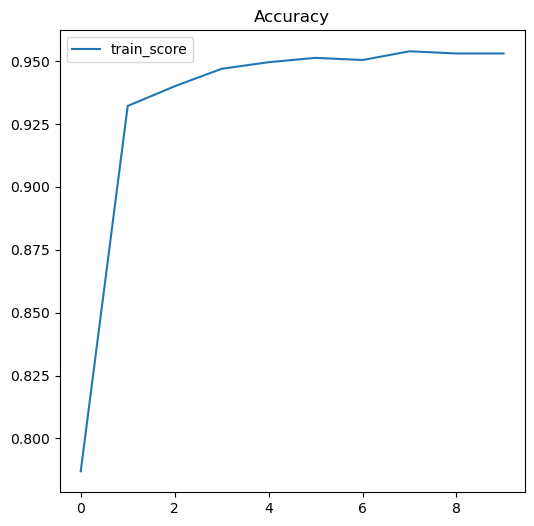

In [137]:
#Visualisation of the Accuracy graph

plt.figure(figsize=(6, 6))
plt.plot(history.history['accuracy'])
plt.title('Accuracy')
plt.legend(['train_score'], loc='upper left')
plt.show()

In [138]:
# Step 6: Make Predictions
'''
Sie wissen wie man trainiert & testet: Split, Cross usw. das machen Sie alleine. Wir schummeln jetzt und verwenden für die Test-Prädiktionen 
jetzt mal den fürs Training verwedneten padding-Datensatz. 


'''
predictions = model.predict(padded_sequences)
predictions

36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step


array([[0.9897327 ],
       [0.94597524],
       [0.99028635],
       ...,
       [0.03571973],
       [0.00879608],
       [0.02982172]], dtype=float32)

Wir sehen die vorhergesagten Ergebnisse: Manche sind näher an 1, manche näher an 0: 

Ein Wert von 0.32 bedeutet, dass das Modell mit 32% Wahrscheinlichkeit vorhersagt, dass die Eingabesequenz zur positiven Klasse gehört (und mit 68% Wahrscheinlichkeit zur negativen Klasse).

Diese Methode gibt die Vorhersagen des Modells für den Testdatensatz zurück. Für binäre Klassifikation (mit binary_crossentropy als Loss) gibt es eine Wahrscheinlichkeit, die angibt, wie wahrscheinlich es ist, dass das Beispiel zur Klasse 1 gehört. Wenn Sie eine Schwellenwertentscheidung treffen möchten, können Sie die Vorhersagen in 0 oder 1 umwandeln (z. B. mit einer Schwelle von 0.5).

In [140]:
#Wir haben 1150 Vorhersagen mit unserem selbst-trainiertem LSTM-Modell erhalten.
predictions.size

1150

In [141]:
# Vorhersagen in 0 oder 1 umwandeln
binary_predictions = (predictions > 0.5).astype(int)

# Beispiel: Ausgabe der ersten 5 binären Vorhersagen
print(binary_predictions[:10])


[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]


Ergebnisse kommen gut hin, da wir unseren Negoisst-Testdatensatz nicht randomisiert haben. Am Anfang Accept, am Ende Reject. 

In [143]:
from sklearn.metrics import classification_report

# Vorhersagen mit den echten Labels vergleichen
print(classification_report(df['NegoOutcomeLabel'], binary_predictions))

              precision    recall  f1-score   support

           0       0.99      0.83      0.90       300
           1       0.94      1.00      0.97       850

    accuracy                           0.95      1150
   macro avg       0.97      0.91      0.94      1150
weighted avg       0.95      0.95      0.95      1150



ERGEBNISSE PASSEN MIT DER OBIG GEZEIGTEN GRAFIK

SIE WISSEN WIE MAN MODELLE TRAINIERT; SIE BITTE ALLE SCHRITTE AUSFÜHRLICH UND SAUBER DURCHFÜHREN; AUCH REPORTING MAXIMUM AUS DEN MODELLEN RAUSHOLEN

## BERT

In [146]:
'''
Let us install the pytorch interface for BERT by Hugging Face. 
(This library contains interfaces for other pretrained language models like OpenAI's GPT and GPT-2.) 

Different ways of implementing BERT, I will only show one way.

Ein Blick auf PyTorck werfen: https://pytorch.org/hub/huggingface_pytorch-transformers/
'''
!pip install pytorch-pretrained-bert pytorch-nlp

In [147]:
#tensorflow oben schon installiert
import tensorflow as tf

import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler

from keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split

#Bert-spezifische Libraries
from pytorch_pretrained_bert import BertTokenizer, BertConfig
from pytorch_pretrained_bert import BertAdam, BertForSequenceClassification

from tqdm import tqdm, trange
import io

In [148]:
#Data Recap

df_nego_message_data['Content']
#df['NegoOutcomeLabel']

ExperimentID
2020_12    dear mr williams happy responsible negotiation...
2020_12    dear mr brown pleased hear youthank last messa...
2020_12    dear mr williams thank quick cooperative respo...
2020_12    dear mr brown concessions last offer showed ri...
2020_12    dear mr williams thank much response happy fou...
                                 ...                        
2020_06    dear chis meyer thank latest offer points comp...
2020_06    dear alex kramerthank much latest offer happy ...
2020_06    dear chris meyerthank fast answer happy found ...
2020_06    dear alex krameri still interested coming join...
2020_06    dear chris meyer im sorry accept less mei unde...
Name: Content, Length: 1150, dtype: object

Preparation of Data for BERT

In [150]:
#Masking erklären in der Theorie für diesen Code

# Create sentence list
#Auf Basis der aufbereiteten V-Nachrichten (siehe oben)
sentences = df_nego_message_data.Content.values

# We need to add special tokens at the beginning and end of each sentence for BERT to work properly
#ALSO HIER SATZ FÜR SATZ PROCESSING VORHANDEN
sentences = ["[CLS] " + sentence + " [SEP]" for sentence in sentences]

#Create label list
labels = df.NegoOutcomeLabel.values

In [151]:
sentences

['[CLS] dear mr williams happy responsible negotiation representative innovax settle last issuesyou certainly aware outbreak bse pandemic great concern association determined stop spread disease vaccination therefore looking come agreement strongly believe able reach agreement suits us communicate well therefore willing communicate openly regarding importance different issues delivery time one important issues us would like vaccine soon possible ideally month another important issue guarantee ideally agree full guarantee since need compensation damages occur moreover price another big concern would suggest price usd two issues certainly important well leave make suggestions values issues publicity future testing looking forward hearing feel issues work deal youwith best regards mr brown [SEP]',
 '[CLS] dear mr brown pleased hear youthank last message unfortunately still open points cannot accept renegotiatedin attachments find first offeri would aim best possible outcome us cooperation

In [152]:
labels

array([1, 1, 1, ..., 0, 0, 0], dtype=int64)

In [153]:
# Next, import the BERT tokenizer, used to convert our text into tokens that correspond to BERT's vocabulary.

''' hier reinschauen und sagen, dass es verschiedene Varianten gibt:
https://huggingface.co/google-bert/bert-base-uncased
https://github.com/google-research/bert/blob/master/README.md
'''

'''
a method call from the Hugging Face transformers library, used to load a pre-trained BERT tokenizer. Here's a breakdown of its components:
1. BertTokenizer:

    This is a class from the Hugging Face transformers library designed to handle the tokenization process for BERT models. 

2. from_pretrained:

    This method is used to load a pre-trained tokenizer. It loads a tokenizer that has been trained on a large corpus of text data and is capable of 
    handling specific details like:
        Tokenizing words into subword units (using WordPiece for BERT).
        Handling special tokens like [CLS], [SEP], and [PAD].
        Mapping tokens to their corresponding vocabulary indices.
    This allows you to reuse a tokenizer that has already been trained on a vast amount of data, saving you the trouble of training a new one from 
    scratch.

3. 'bert-base-uncased':

    This is the specific pre-trained model variant that you're loading the tokenizer for. In this case:
        bert-base refers to the base version of BERT with 110 million parameters.
        uncased means that the model and tokenizer are case-insensitive (it doesn't differentiate between uppercase and lowercase letters).
    There are other variants of BERT, such as bert-base-cased (which is case-sensitive), or larger models like bert-large-uncased.
'''

#separater Tokenizer von BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased', do_lower_case=True)
tokenized_texts = [tokenizer.tokenize(sent) for sent in sentences]
print (tokenized_texts[0])

['[CLS]', 'dear', 'mr', 'williams', 'happy', 'responsible', 'negotiation', 'representative', 'inn', '##ova', '##x', 'settle', 'last', 'issues', '##you', 'certainly', 'aware', 'outbreak', 'bs', '##e', 'pan', '##de', '##mic', 'great', 'concern', 'association', 'determined', 'stop', 'spread', 'disease', 'va', '##cci', '##nation', 'therefore', 'looking', 'come', 'agreement', 'strongly', 'believe', 'able', 'reach', 'agreement', 'suits', 'us', 'communicate', 'well', 'therefore', 'willing', 'communicate', 'openly', 'regarding', 'importance', 'different', 'issues', 'delivery', 'time', 'one', 'important', 'issues', 'us', 'would', 'like', 'vaccine', 'soon', 'possible', 'ideally', 'month', 'another', 'important', 'issue', 'guarantee', 'ideally', 'agree', 'full', 'guarantee', 'since', 'need', 'compensation', 'damages', 'occur', 'moreover', 'price', 'another', 'big', 'concern', 'would', 'suggest', 'price', 'usd', 'two', 'issues', 'certainly', 'important', 'well', 'leave', 'make', 'suggestions', 'va

In [154]:
#Comment zu ##-Wörter von vorhergehender Zeile
'''
The BERT tokenization function, on the other hand, will first breaks the word into two subwoards, namely characteristic and ##ally, 
where the first token is a more commonly-seen word (prefix) in a corpus, and the second token is prefixed by two hashes ## to indicate that it is 
a suffix following some other subwords.
'''

'\nThe BERT tokenization function, on the other hand, will first breaks the word into two subwoards, namely characteristic and ##ally, \nwhere the first token is a more commonly-seen word (prefix) in a corpus, and the second token is prefixed by two hashes ## to indicate that it is \na suffix following some other subwords.\n'

In [155]:
#Length of the sentence inputs: 

''' In summary, the MAXLEN of BERT is 512 tokens (subwords können auch tokens sein), and this is a crucial constraint to consider when working with BERT models.

Although we can have variable length input sentences, BERT does requires our input arrays to be the same size. 
I addressed this by first choosing a maximum sentence length, and then padding and truncating our inputs until every input sequence is of the 
same length.

--> wenn kürzer: dann am Ende einfach 0en einfügen, wenn größer dann hinten abschneiden --> es gibt mehrere Truncation-Strategien --> selbst einlesen

pad_sequences is a utility function that we're borrowing from Keras. It simply handles the truncating and padding of Python lists.
'''

" In summary, the MAXLEN of BERT is 512 tokens (subwords können auch tokens sein), and this is a crucial constraint to consider when working with BERT models.\n\nAlthough we can have variable length input sentences, BERT does requires our input arrays to be the same size. \nI addressed this by first choosing a maximum sentence length, and then padding and truncating our inputs until every input sequence is of the \nsame length.\n\n--> wenn kürzer: dann am Ende einfach 0en einfügen, wenn größer dann hinten abschneiden --> es gibt mehrere Truncation-Strategien --> selbst einlesen\n\npad_sequences is a utility function that we're borrowing from Keras. It simply handles the truncating and padding of Python lists.\n"

In [156]:
# Set the maximum sequence length. 
# In the original paper, the authors used a length of 512.
MAX_LEN = 512

# Use the BERT tokenizer to convert the tokens to their index numbers in the BERT vocabulary
input_ids = [tokenizer.convert_tokens_to_ids(x) for x in tokenized_texts]

Token indices sequence length is longer than the specified maximum  sequence length for this BERT model (560 > 512). Running this sequence through BERT will result in indexing errors
Token indices sequence length is longer than the specified maximum  sequence length for this BERT model (1546 > 512). Running this sequence through BERT will result in indexing errors
Token indices sequence length is longer than the specified maximum  sequence length for this BERT model (721 > 512). Running this sequence through BERT will result in indexing errors
Token indices sequence length is longer than the specified maximum  sequence length for this BERT model (817 > 512). Running this sequence through BERT will result in indexing errors


In [157]:
# Pad our input tokens
'''
TRUNCATING.
truncating='pre': This means truncating (cutting) the beginning (pre) of the sequence. If a sequence is longer than maxlen, 
tokens from the start of the sequence are removed.
Example: If maxlen=5 and the input sequence is [1, 2, 3, 4, 5, 6, 7], truncating from the beginning would result in [3, 4, 5, 6, 7].

truncating='post': This means truncating (cutting) the end (post) of the sequence. If a sequence exceeds the maxlen, tokens from the end of the 
sequence are removed.
Example: If maxlen=5 and the input sequence is [1, 2, 3, 4, 5, 6, 7], truncating from the end would result in [1, 2, 3, 4, 5].

PADDING:
padding='post': This means padding (adding extra tokens) at the end of the sequence. If a sequence is shorter than the maxlen, 
padding tokens are added at the end.
If maxlen=5 and the input sequence is [1, 2], padding it post would result in [1, 2, 0, 0, 0], assuming 0 is the padding token.
'''

input_ids = pad_sequences(input_ids, maxlen=MAX_LEN, dtype="long", truncating="post", padding="post")

In [158]:
# Create attention masks
attention_masks = []

'''
The code is creating attention masks where each mask contains 1 for real tokens and 0 for padding tokens.
1.0 represents a valid token.
0.0 represents a padding token.

For the first sequence [101, 2009, 2003, 1037, 6273, 102, 0, 0], the mask would be [1, 1, 1, 1, 1, 1, 0, 0]. 
The first 6 tokens are valid, and the last 2 are padding.
'''

# Create a mask of 1s for each token followed by 0s for padding
for seq in input_ids:
  seq_mask = [float(i>0) for i in seq]
  attention_masks.append(seq_mask)

In [159]:

# Use train_test_split to split our data into train and validation sets for training

train_inputs, validation_inputs, train_labels, validation_labels = train_test_split(input_ids, labels, random_state=42, test_size=0.1)
train_masks, validation_masks, _, _ = train_test_split(attention_masks, input_ids, random_state=42, test_size=0.1)

In [160]:
train_inputs

array([[ 101, 6203, 2829, ...,    0,    0,    0],
       [ 101, 6203, 3766, ...,    0,    0,    0],
       [ 101, 6203, 4074, ...,    0,    0,    0],
       ...,
       [ 101, 6203, 3782, ...,    0,    0,    0],
       [ 101, 6203, 2829, ...,    0,    0,    0],
       [ 101, 6203, 3782, ...,    0,    0,    0]])

In [161]:
#Anzahl Sätze für Training
train_inputs.size

529920

In [162]:
train_masks

[[1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,

In [163]:
validation_inputs

array([[ 101, 6203, 2720, ...,    0,    0,    0],
       [ 101, 6203, 2720, ...,    0,    0,    0],
       [ 101, 6203, 2720, ...,    0,    0,    0],
       ...,
       [ 101, 6203, 2720, ...,    0,    0,    0],
       [ 101, 6203, 2829, ...,    0,    0,    0],
       [ 101, 4931, 3782, ...,    0,    0,    0]])

In [164]:
#Anzahl Sätze für Validation/Testing
validation_inputs.size

58880

Create & Prepare Dataset for BERT-Processing

In [166]:
# Convert all of our data into torch tensors, the required datatype for our model
'''
The torch.tensor() function in PyTorch is used to create a tensor from a variety of input data types (e.g., lists, NumPy arrays, etc.).

A tensor is a multi-dimensional array used to store data. In mathematical terms, a tensor is a generalization of scalars, vectors, 
and matrices to potentially higher dimensions. Tensors are fundamental data structures in deep learning frameworks like PyTorch and 
TensorFlow because they are used to represent data and perform computations, especially in neural networks.
'''

train_inputs = torch.tensor(train_inputs)
validation_inputs = torch.tensor(validation_inputs)
train_labels = torch.tensor(train_labels)
validation_labels = torch.tensor(validation_labels)
train_masks = torch.tensor(train_masks)
validation_masks = torch.tensor(validation_masks)

In [167]:
# Select a batch size for training. For fine-tuning BERT on a specific task, the authors recommend a batch size of 16 or 32
'''
batch size refers to the number of input sequences (e.g., tokenized sentences or text) processed together 
in one forward pass through the model during training
'''
batch_size = 32

# Create an iterator of our data with torch DataLoader. This helps save on memory during training because, unlike a for loop, 
# with an iterator the entire dataset does not need to be loaded into memory

train_data = TensorDataset(train_inputs, train_masks, train_labels)
'''randomly samples the data from the provided dataset during each epoch of training. 
This means that it will shuffle the dataset before iterating over it, ensuring that the model does not learn any order-based patterns from the data.
'''
train_sampler = RandomSampler(train_data)
#provides an efficient way to load and batch data for model training or evaluation. 
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)

validation_data = TensorDataset(validation_inputs, validation_masks, validation_labels)
#hier brauchen wir keine Randomisierung mehr, da es nun um die Validierung des Test-Sets geht
validation_sampler = SequentialSampler(validation_data)
validation_dataloader = DataLoader(validation_data, sampler=validation_sampler, batch_size=batch_size)

Training of BERT

In [169]:
# Load BertForSequenceClassification, the pretrained BERT model with a single linear classification layer on top. 
'''
There are a few different pre-trained BERT models available. "bert-base-uncased" means the version that has only lowercase letters ("uncased") 
and is the smaller version of the two ("base" vs "large"). --> large selbst ausprobieren
'''

model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)

Optimizer and Scheduler

In [171]:
!pip install transformers

In [172]:
from transformers import AdamW, get_scheduler

#man kann hier an dieser Stelle wie bei PDA-Sets zum evaluieren defiieren und dann übergeben
#machen wir jetzt nicht
optimizer = AdamW(model.parameters(), lr=2e-5)

num_training_steps = len(train_dataloader) * 3  # 3 epochs
scheduler = get_scheduler(
    "linear", optimizer=optimizer, num_warmup_steps=0, num_training_steps=num_training_steps
)

Training

In [181]:
from torch.nn import CrossEntropyLoss
from torch.optim import AdamW

# Device setup
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

# Training loop
epochs = 2
model.train()

for epoch in range(epochs):
    for batch in train_dataloader:
        b_input_ids, b_input_mask, b_labels = batch
        '''
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        '''

        # Forward pass
        loss = model(b_input_ids, attention_mask=b_input_mask, labels=b_labels)
        #logits = loss.logits

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch + 1} completed. Loss: {loss.item()}")

KeyboardInterrupt: 

In [ ]:
'''
obigen Code nach dem Laden in Anlehnung an: 

https://www.kaggle.com/code/pavansanagapati/knowledge-graph-nlp-tutorial-bert-spacy-nltk#BERT:-Bidirectional-Encoder-Representations-from-Transformers

und ChatGPT-Beispiel (siehe unten) fortführen
'''

In [ ]:
#aus ChatGPT

#Evaluation
model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in test_dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        predictions = torch.argmax(logits, dim=-1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate accuracy
accuracy = accuracy_score(all_labels, all_predictions)
print(f"Accuracy: {accuracy}")

# Classification report
print(classification_report(all_labels, all_predictions, target_names=["Negative", "Positive"]))